<h1>Speech recognition with the Whisper model</h1>

In [8]:
#BEFORE RUNNING THIS ON YOUR OWN DEVICE PREREQUISITET INSTALLS ARE:

%pip install torch
%pip install transformers
%pip install librosa
%pip install ipywidgets
%pip install PySoundFile
%pip install sentencepiece
%pip install sacremoses

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


<h2>Business understanding</h2>

In this document, we go through basic voice recognition with the Whisper model. We use self-recorded Finnish sentences as the audio source. The sentence used in the document roughly translates as, "Hey artificial intelligence, how are you? I'm doing well. Are you able to understand what I am saying to you?"

There are six audio files. The audio files consist of three different people speaking the exact same sentence, and also one with an Eastern Finnish dialect. There are also two with added noise and music to one of the speakers sentences.

The goal is to see the performance of different Whisper models and how they manage to correctly transcribe the audio. This document also covers what a Mel-spectrogram is and why it is used with the Whisper transformer model.

<h2>Data understanding and preparation</h2>

In [1]:
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import WhisperProcessor, WhisperForConditionalGeneration

# Set the audio filenames
af_01 = "audio/01_plain_finnish_speaker_01.wav"
af_02 = "audio/02_plain_finnish_speaker_02.wav"
af_03 = "audio/03_plain_finnish_speaker_03.wav"
af_04 = "audio/04_plain_finnish_and_noise.wav"
af_05 = "audio/05_plain_finnish_and_music.wav"
af_06 = "audio/06_dialect_finnish.wav"

First step is to assign the audio files to a variable.

In [2]:
# Load audio files
y_01, sr_01 = librosa.load(af_01, sr=16000)
y_02, sr_02 = librosa.load(af_02, sr=16000)
y_03, sr_03 = librosa.load(af_03, sr=16000)
y_04, sr_04 = librosa.load(af_04, sr=16000)
y_05, sr_05 = librosa.load(af_05, sr=16000)
y_06, sr_06 = librosa.load(af_06, sr=16000)

# Display audios for playback
print("\nPlay the \"Plain finnish speaker 01\" audio:")
display(Audio(y_01, rate=sr_01))

print("\nPlay the \"Plain finnish speaker 02\" audio:")
display(Audio(y_02, rate=sr_02))

print("\nPlay the \"Plain finnish speaker 03\" audio:")
display(Audio(y_03, rate=sr_03))

print("\n\nPlay the \"Plain finnish speaker 01 poluted with noise\" audio:")
display(Audio(y_04, rate=sr_04))

print("\n\nPlay the \"Plain finnish speaker 01 with background music\" audio:")
display(Audio(y_05, rate=sr_05))

print("\n\nPlay the \"Finnish spoken with eastern finland dialect\" audio:")
display(Audio(y_06, rate=sr_06))


# Print first audio statistics
duration = librosa.get_duration(y=y_01, sr=sr_01)

print("\n\nAudio 01:\"Plain finnish\" stats:")
print(f"Duration: {duration:.2f} seconds")
print(f"Sample rate: {sr_01} Hz")
print(f"Audio shape: {y_01.shape}")
print(f"Data type: {y_01.dtype}")


Play the "Plain finnish speaker 01" audio:



Play the "Plain finnish speaker 02" audio:



Play the "Plain finnish speaker 03" audio:




Play the "Plain finnish speaker 01 poluted with noise" audio:




Play the "Plain finnish speaker 01 with background music" audio:




Play the "Finnish spoken with eastern finland dialect" audio:




Audio 01:"Plain finnish" stats:
Duration: 6.40 seconds
Sample rate: 16000 Hz
Audio shape: (102381,)
Data type: float32


Secondly we print out the audio files and the statistics of the first audio file.



"Plain finnish" audio waveform and mel-spectrogram:




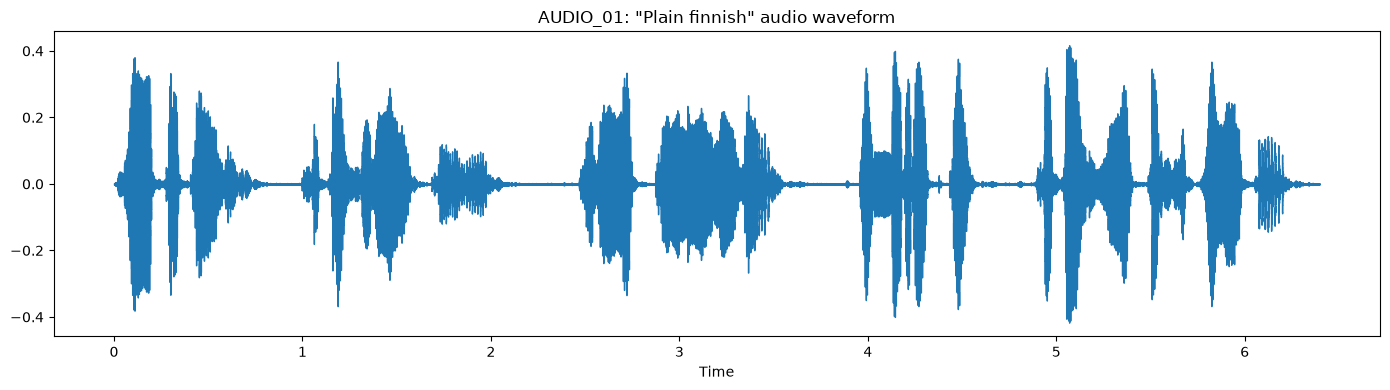

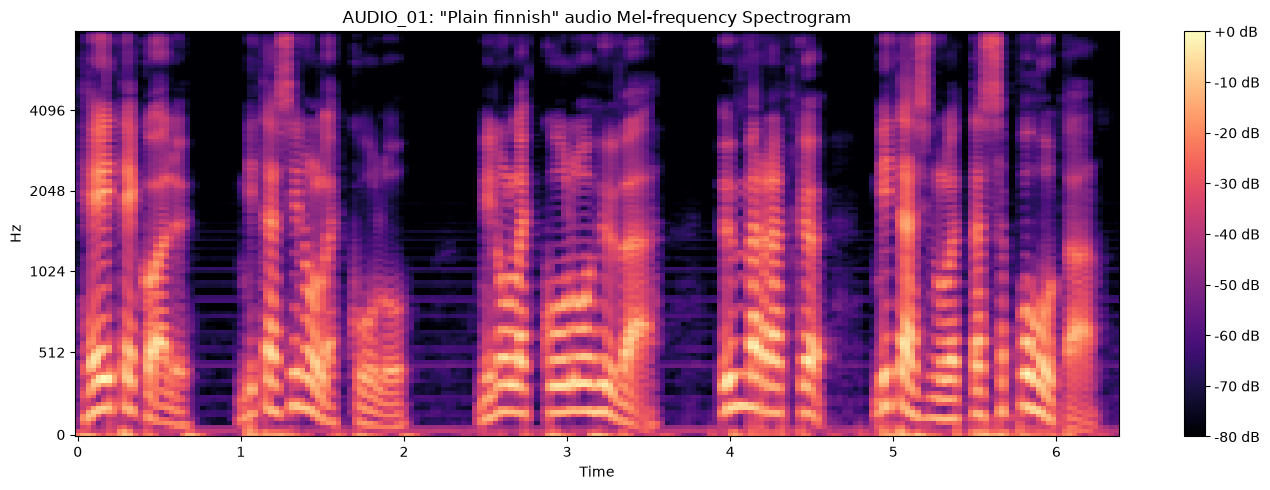

In [4]:
print("\n\n\"Plain finnish\" audio waveform and mel-spectrogram:\n\n")

# Plot waveform
plt.figure(figsize=(14, 4))
librosa.display.waveshow(y_01, sr=sr_01)
plt.title('AUDIO_01: "Plain finnish\" audio waveform')
plt.tight_layout()
plt.show()

# Create mel spectrogram
plt.figure(figsize=(14, 5))
S = librosa.feature.melspectrogram(y=y_01, sr=sr_01, n_mels=128)
S_dB = librosa.power_to_db(S, ref=np.max)
librosa.display.specshow(S_dB, y_axis='mel', x_axis='time', sr=sr_01)
plt.colorbar(format='%+2.0f dB')
plt.title('AUDIO_01: "Plain finnish\" audio Mel-frequency Spectrogram')
plt.tight_layout()
plt.show()

<h3>What is Mel Spectogram and why does Whisper -model use it?</h3>

A Mel Spectrogram is a visual representation of audio that shows how the frequencies of a sound change over time. Whisper uses it to convert raw audio into a format that a neural network can process more efficiently for speech recognition.

<h4>Why specificly Mel Spectrogram?</h4>

Why not just regular waveform? The answer lies in the information that can be seen from the represenation. Regular waveform has 2D information: 

- X-axis as time.
- Y-axis as amplitude.

On the other hand Mel Spectrogram has 3D information:

- X-axis as time
- Y-axis as frequency
- Color indicates the strength of each frequency

This allows us to see how the frequency content of speech changes over time. Whisper is a Transformer-based encoder-decoder model. Its input is not directly the raw audio waveform. Instead, the audio goes through a preprocessing pipeline. Whisper uses Mel Spectrograms because it provides a structured and speech-relevant representation of audio that its transformer encoder can learn from.

<h2>3. Data preparation</h2>

In [15]:
# Three choices: NVIDIA-GPU, Apple-GPU tai CPU
device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available()
          else "cpu")

print(f"Using device: {device}")

Using device: cpu


<h2>Modeling</h2>

In [14]:
model_name = "openai/whisper-tiny"   # different models are: tiny, base, small, medium, large-v3
processor = WhisperProcessor.from_pretrained(model_name)
model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

#truncation=True, Whisper will not be able to handle longer than 30 second long files and it wil clip it.
#truncation=False, Whisper will handle longer tha 30 second long audio files
inputs = processor(y_03, sampling_rate=sr_03, return_tensors="pt",
                   truncation=True, padding="longest",
                   return_attention_mask=True).to(device, model.dtype)

with torch.no_grad():
    generated_ids = model.generate(**inputs, language="fi", task="transcribe",
                                   return_timestamps=False)   # return_timestamps has to be set to true if used longer than 30s audiofiles!!!

transcription = processor.batch_decode(
    generated_ids, skip_special_tokens=True,
    clean_up_tokenization_spaces=False)[0].strip()

print("FINNISH TRANSCRIPTION:")
print("=" * 50)
print(transcription)

Loading weights:   0%|          | 0/167 [00:00<?, ?it/s]

FINNISH TRANSCRIPTION:
Hei tekoälle mitä sinulle kuuluu, minulle kuuluu hyvää. En määrätkö mitä sinulle tässä puhutaan.


<h3>Results with different sized models:</h3>

<h4>af_01: "Plain finnish speaker 01"</h4>

- Correct: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Tiny transcription: </h5>

- Result: "Heitekäli, mitä sinulle kulu, minulle kulu huvaa, ymmärratkö, mitä sinulle tässä puhutaan."

<h5>Base transcription: </h5>

- Result: "Heitekoily, mitä sinulle kuuluu? Minulle kuuluu hyvä. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Small transcription: </h5>

- Result: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h4>af_02: "Plain finnish speaker 02"</h4>

- Correct: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Tiny transcription: </h5>

- Result: "Hei tekoälle mitä sinulle kuuluu, minulle kuuluu hyvää. En määrätkö mitä sinulle tässä puhutaan."

<h5>Base transcription: </h5>

- Result: "Heitekoa lyt? Mitä sinulle kuuluu? Minulle kuuluu hyvää? Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Small transcription: </h5>

- Result: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h4>af_03: "Plain finnish speaker 03"</h4>

- Correct: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Tiny transcription: </h5>

- Result: "Heitekäli, mitä sinulle kulu, minulle kulu huvaa, ymmärratkö, mitä sinulle tässä puhutaan."

<h5>Base transcription: </h5>

- Result: "Heitekoily, mitä sinulle kuuluu? Minulle kuuluu hyvä. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Small transcription: </h5>

- Result: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h4>af_04: "Plain finnish with noise pollution"</h4>

- Correct: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Tiny transcription: </h5>

- Result: "Heiteko alue, mitä sinulle kouluu? Minulle kuuluu hyvä. Ymmärratkö, mitä sinulle tässä onutaa?"

<h5>Base transcription: </h5>

- Result: "Heitekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?."

<h5>Small transcription: </h5>

- Result: "Heitekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<h5>Medium transcription: </h5>

- Result: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö, mitä sinulle tässä puhutaan?"


<h4>af_05: "Plain finnish with background music"</h4>

- Correct: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö mitä sinulle tässä puhutaan?"

<b>Tiny transcription: </b>

- Result: "Heitekoulu, mitä sinulle kuulu, minulle kuulu huvaa, ymmärratkö, mitä sinulle tässä pohutaan."

<b>Base transcription: </b>

- Result: "Heitekoily, mitä sinulle kuuluu? Minulle kuuluu hyvä. Ymmärrätkö, mitä sinulle tässä puhutaan?"

<b>Small transcription: </b>

- Result: "Hei tekoäly, mitä sinulle kuuluu? Minulle kuuluu hyvää. Ymmärrätkö, mitä sinulle tässä puhutaan?"


<h4>af_06: "Finnish spoken with eastern finland dialect"</h4>

- Correct: "No terveppä terve tekoäly, mitäpä siulle kuuluu? Miulle kuulluu oikkeen hyvvee. Ymmärrätkö sie mitä myö siulle tässä haastellaan?"

<b>Tiny transcription: </b>

- Result: "on tervepä tervettekoa ly, mitä päässi ulle kuulu, mielenkuulu oikein hyvää, ymmärätkö siihen, mitä myötässä siullaan haastellaan."

<b>Base transcription: </b>

- Result: "No terveppä tervetekoily, mitä pääsi ole kuuluu? Me olemme kuuluu oikeehyvää! Ymmärrätkö siihen, mitä myö tässä siulle haastellaan?"

<b>Small transcription: </b>

- Result: "No terveppä tervetekoäly, mitä pääsiuule kuuluu? Miule kuuluu oikein hyvää. Ymmärrätkö siihen, mitä myötässä siule haastellaan?"

<b>Medium transcription: </b>

- Result: "No tervepä tervettekoäly! Mitäpä sille kuuluu? Mille kuuluu oikein hyvää! Ymmärrätkö siihen, mitä me tässä sille haastellaan?"

<b>Large-v3 transcription: </b>

- Result: "No terveppä tervetekoäly. Mitäpä siulle kuuluu? Miulle kuuluu oikein hyvää. Ymmärrätkö siihen, mitä me tässä siulle haastellaan?"

<h2>Evaluation</h2>

We ran our audio files through Whisper's models: tiny, base, small, medium, & large-v3. The first three: tiny, base, and small are quite lightweight and load relatively quickly. As for the medium and large versions, they are heavier and need more computing power.

The larger the model, the more precise predictions it could make. The small model proved to be the most efficient one for our experiments; it could transcribe plain Finnish speech correctly from three different people and also one with music in the background, which was quite impressive.

The medium model handled the audio file with background noise well. All of the models guessed the Finnish dialect file incorrectly, even though the large-v3 version got really close! The tiny and base versions could transcribe some of the words correctly; base was slightly more precise, as it could understand that the last sentence was a question, whereas tiny did not recognize it.

Whisper's speech recognition is not without error. It can interpret badly articulated words incorrectly and transcribe words that were not there in the first place. It has trouble with rarer vocabulary, dialects, and poor-quality audio. Also, the heavier versions take a longer time to process and take up more memory, so their real-time usage can become tricky.

It can prove to be a really useful tool in situations where slight errors can occur or where the output will be checked by a real human afterwards.

Something that would be useful to experiment with next would be different and longer sentences, and more languages.